# Week 5 — Encoder and decoder, open loop

**Goal:** connect arm and brain in one direction at a time. Logged arm states go *into* the brain; nothing comes back out to the arm yet. The question: **do the brain's output neurons carry information about the task state?**

| piece | what it is (code in `sim/interface.py`) |
|---|---|
| **Encoder** | 4 scalar signals (cube − gripper x, y, z, and gripper width) → a Poisson rate on each of the 335 JO-C/E neurons. Each signal drives a *push* channel at 150 + 125·s Hz and a *pull* channel at 150 − 125·s Hz, so the **total input never changes** with the task state; the brain can only carry information by routing it. Positions are squashed with tanh (5 cm scale in x, y; 8 cm in z) so resolution is highest near the cube. |
| **Channels** | *wiring*: JO neurons grouped by whom they synapse onto (recursive split on their output connectivity); *random*: a random split (control). Step 2 picks one by a fixed rule. |
| **BrainIO** | advances the full network on the Numba engine one 40 ms control step at a time, exactly as the week 6 closed loop will. |
| **Decoder** | firing rate of each output neuron over the last 20, 40 or 50 ms. Primary readout: the 68 descending-neuron candidates from week 1 (the week 2 decision). Also tested: the 81 front-leg MNs and all descending neurons. |

**Steps:** 1 encoder design · 2 tuning sweeps and encoder choice · 3 replay of logged episodes · 4 decoding (the deliverable) · 5 latency · 6 shuffled-wiring control · 7 summary figure.

**Pass rule, fixed before any results** (primary readout = DN candidates, 40 ms window, cross-validated by episode):
1. for **each** of the 4 signals, R² beats **every** one of 20 episode-swap nulls (p < 0.05), and
2. the **median R² across the 4 signals is ≥ 0.5**.

If it fails: all-DN readout passes → widen the readout in week 6 (cheap). All brain readouts fail but the JO-input ceiling passes → information is lost inside the brain, so revisit the input choice (the plan's stated risk). Ceiling fails too → the encoder itself is too noisy.

**Where to run:** the laptop (`sim-env`), since the closed loop will run there. About **35 min** in total (Step 3 and Step 6 replays are about 13 min each). Set `QUICK = True` first for a 5-minute smoke test. Colab also works (about 1.3× slower; put `pick_place_expert.npz` on Drive).

### Setup

In [1]:
import sys, subprocess, os
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
    try:
        import brian2, numba
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'brian2', 'numba'], check=True)
        print("brian2/numba installed -> restarting runtime. When it reconnects, choose Runtime -> Run all again.")
        os.kill(os.getpid(), 9)
except ImportError:
    IN_COLAB = False

from pathlib import Path
BRAIN = Path('/content/drive/MyDrive/arm_simulation/brain') if IN_COLAB else Path.home() / 'arm_simulation/brain'
DATA = BRAIN / 'data'
sys.path.insert(0, str(BRAIN))

# Week 4 dataset: the first path that exists is used. If yours is elsewhere, set DATASET by hand.
CANDIDATES = [BRAIN.parent / 'results/pick_place_expert.npz', DATA / 'pick_place_expert.npz',
              BRAIN.parent / 'results/pick_place_expert.npz']
DATASET = next((p for p in CANDIDATES if p.exists()), None)

QUICK = False        # True: 12 episodes, 5 nulls, no shuffled control (about 5 min) - a smoke test only
RUN_SHUFFLE = True   # Step 6, about 13 min

for p in ['sim/lif.py', 'sim/lif_numba.py', 'sim/interface.py', 'sim/readout.py',
          'data/weights_male-cns_v1.0/meta.json', 'data/shortlist_week1.csv', 'data/wsyn_choice.json']:
    print(f"{p:45s} {'ok' if (BRAIN / p).exists() else 'MISSING'}")
print(f"{'week 4 dataset':45s} {DATASET if DATASET else 'MISSING - set DATASET in this cell'}")

sim/lif.py                                    ok
sim/lif_numba.py                              ok
sim/interface.py                              ok
sim/readout.py                                ok
data/weights_male-cns_v1.0/meta.json          ok
data/shortlist_week1.csv                      ok
data/wsyn_choice.json                         ok
week 4 dataset                                /home/notlord/arm_simulation/results/pick_place_expert.npz


### Load weights, neuron groups, dataset

In [2]:
import json, time, gc
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import warnings; warnings.filterwarnings('ignore', module='brian2')
from sim.lif import WeightSet, shuffle_sub, peak_mem_gb
from sim.lif_numba import NumbaLIF
from sim.interface import (SIGNALS, SCALES, normalise, denormalise, wiring_channels, random_channels,
                           channel_overlap, Encoder, BrainIO, Decoder, replay, tuning_sweep)
from sim.readout import (cv_predict, cv_r2, r2, cv_classify, null_r2, lagged, ridge_fit_predict)

T_START = time.perf_counter()
HOST = 'colab' if IN_COLAB else 'laptop'
OUT = DATA / 'week5'; OUT.mkdir(exist_ok=True)

ws = WeightSet(DATA / 'weights_male-cns_v1.0')
W = json.loads((DATA / 'wsyn_choice.json').read_text())['w_scale']
JO = ws.by_type(r'^JO-(C|E)', cls='cb_sensory')
shortlist = pd.read_csv(DATA / 'shortlist_week1.csv')
g2i = pd.Series(ws.neurons.index, index=ws.neurons.bodyId)
DN_cand = g2i.loc[shortlist.query("group == 'middle_descending'").bodyId].to_numpy()
LEG_MN = g2i.loc[shortlist.query("group == 'output_T1_leg_MN'").bodyId].to_numpy()
ALL_DN = ws.idx(ws.neurons['cls'].astype(str).str.contains('descending', case=False))
print("classes containing 'descending':", ws.neurons.loc[ALL_DN, 'cls'].value_counts().to_dict())
if len(ALL_DN) == 0:
    print("  none found -> the 'all DNs' readout falls back to the DN candidates")
    ALL_DN = DN_cand
print(f"w_scale {W}, JO-C/E {len(JO)}, DN candidates {len(DN_cand)}, leg MNs {len(LEG_MN)}, all DNs {len(ALL_DN)}")

# dataset (week 4): replay successful VALIDATION episodes, a fixed random subset
D = np.load(DATASET)
OBS_NAMES = [str(x) for x in D['obs_names']]
ep_all = D['episode']
ok_ep = np.flatnonzero(D['ep_is_val'] & D['ep_success'])
N_EP = 12 if QUICK else 60
EPS = np.sort(np.random.default_rng(0).choice(ok_ep, min(N_EP, len(ok_ep)), replace=False))
ROWS = np.concatenate([np.flatnonzero(ep_all == e) for e in EPS])   # dataset rows in replay order
S_ALL = normalise(D['obs'], OBS_NAMES)
K = len(SIGNALS)
PHASE_NAMES = [str(x) for x in D['phase_names']] if 'phase_names' in D.files else \
    ["reach", "descend", "close", "lift", "carry", "lower", "release", "retreat"]
noisy = D['ep_noisy'][EPS].sum() if 'ep_noisy' in D.files else 'n/a'
print(f"dataset: {len(np.unique(ep_all))} episodes; replaying {len(EPS)} val episodes "
      f"({len(ROWS)} steps, {noisy} with action noise) = {len(ROWS) * 0.04 + len(EPS) * 0.2:.0f} s of brain time")

classes containing 'descending': {'descending_neuron': 1314, 'sensory_descending': 12, 'efferent_descending': 4, 'descending_neuron_tbc': 2}
w_scale 0.7, JO-C/E 335, DN candidates 68, leg MNs 81, all DNs 1332
dataset: 1000 episodes; replaying 60 val episodes (3877 steps, 27 with action noise) = 167 s of brain time


In [3]:
# plot style (validated reference palette; text in ink colours, never series colours)
C = dict(blue='#2a78d6', orange='#eb6834', aqua='#1baf7a', yellow='#eda100', violet='#6250d6',
         gray='#9a9893', ink='#0b0b0b', ink2='#52514e', grid='#e6e5e1')
SEQ = LinearSegmentedColormap.from_list('seq', ['#f4f8fd', '#9ec5f4', '#3987e5', '#1c5cab', '#0d366b'])
DIV = LinearSegmentedColormap.from_list('div', ['#104281', '#6da7ec', '#f0efec', '#ee8b8a', '#a12a2a'])
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'font.size': 9, 'axes.titlesize': 10,
                     'axes.titleweight': 'bold', 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': C['ink2'], 'axes.labelcolor': C['ink2'], 'xtick.color': C['ink2'],
                     'ytick.color': C['ink2'], 'axes.grid': True, 'grid.color': C['grid'], 'grid.linewidth': 0.6,
                     'axes.axisbelow': True, 'legend.frameon': False, 'lines.linewidth': 2})
SIG_LABEL = {'cube_rel_x': 'cube − gripper x', 'cube_rel_y': 'cube − gripper y',
             'cube_rel_z': 'cube − gripper z', 'grip_width': 'gripper width'}
LBL = [SIG_LABEL[s] for s in SIGNALS]

## Step 1: encoder design

Two channel assignments for the 335 JO-C/E neurons, 8 channels of about 42 neurons (4 signals × push/pull):
- **wiring**: each JO neuron is described by its row of output synapses. The population is split in half along the first principal component of those rows, then each half again, three times. The first split decides push vs pull, so the two halves of every signal reach the most different downstream partners.
- **random**: seeded random equal split.

The overlap plot shows how similar each pair of channels' outputs are (cosine similarity of summed output synapses; 1 = same partners). Lower off-diagonal means the brain receives more distinguishable inputs.

JO-C/E type (and side) per wiring channel:


wiring channel,cube − gripper x +,cube − gripper y +,cube − gripper z +,gripper width +,cube − gripper x −,cube − gripper y −,cube − gripper z −,gripper width −
row_0,,,,,,,,
JO-CA1 None,0,0,0,0,8,0,0,2
JO-CA2 None,0,0,0,0,9,0,0,0
JO-CL None,5,8,0,0,0,6,0,0
JO-CM None,15,0,1,0,1,5,4,4
JO-ED1 None,6,3,0,0,6,1,0,2
JO-ED2_a None,3,1,6,5,11,5,3,4
JO-ED2_b None,0,0,9,1,0,0,8,3
JO-ED2_c None,5,0,0,0,6,3,0,0
JO-EV1 None,3,28,0,0,0,19,0,0


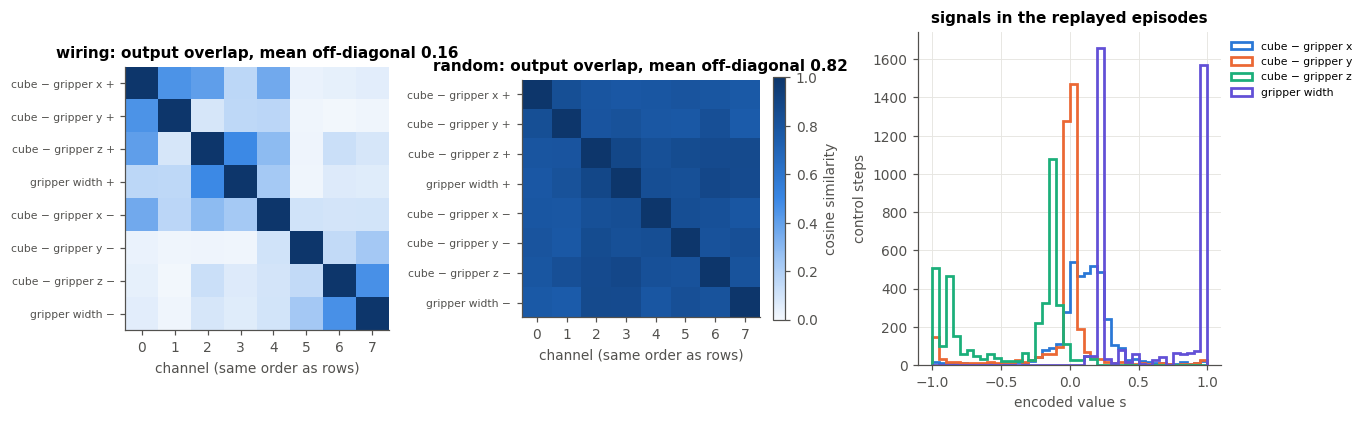

In [4]:
lab_w = wiring_channels(ws, JO, 2 * K)
lab_r = random_channels(len(JO), 2 * K, seed=0)
ENC = {'wiring': Encoder(JO, lab_w, kind='wiring'), 'random': Encoder(JO, lab_r, kind='random')}
CH_NAMES = [f"{SIG_LABEL[s]} +" for s in SIGNALS] + [f"{SIG_LABEL[s]} −" for s in SIGNALS]

side_col = next((c for c in ('somaSide', 'side', 'soma_side') if c in ws.neurons.columns), None)
key = ws.neurons.loc[JO, 'type'].astype(str)
if side_col:
    key = key + ' ' + ws.neurons.loc[JO, side_col].astype(str)
comp = pd.crosstab(key.values, pd.Series(np.array(CH_NAMES)[lab_w], name='wiring channel'))[CH_NAMES]
print("JO-C/E type (and side) per wiring channel:")
display(comp)

ov = {k: channel_overlap(ws, JO, e.labels) for k, e in ENC.items()}
off = ~np.eye(2 * K, dtype=bool)
fig, axs = plt.subplots(1, 3, figsize=(12.5, 3.9), gridspec_kw=dict(width_ratios=[1, 1, 1.15]))
for ax, (k, m) in zip(axs, ov.items()):
    im = ax.imshow(m, cmap=SEQ, vmin=0, vmax=1)
    ax.set_xticks(range(2 * K), [f"{i}" for i in range(2 * K)]); ax.set_yticks(range(2 * K), CH_NAMES, fontsize=7)
    ax.set_title(f"{k}: output overlap, mean off-diagonal {m[off].mean():.2f}"); ax.grid(False)
    ax.set_xlabel('channel (same order as rows)')
fig.colorbar(im, ax=axs[1], fraction=0.046, label='cosine similarity')
ax = axs[2]
S_rep = S_ALL[ROWS]
cols = [C['blue'], C['orange'], C['aqua'], C['violet']]
for k in range(K):
    ax.hist(S_rep[:, k], bins=np.linspace(-1, 1, 41), histtype='step', lw=1.8, color=cols[k], label=LBL[k])
ax.set_xlabel('encoded value s'); ax.set_ylabel('control steps'); ax.set_title('signals in the replayed episodes')
ax.legend(fontsize=7, loc='upper left', bbox_to_anchor=(1.0, 1.0))
fig.tight_layout(); fig.savefig(OUT / 'step1_encoder.png'); plt.show()
for k, e in ENC.items():
    e.to_json(OUT / f'encoder_{k}.json', ws)

## Step 2: tuning sweeps and encoder choice

Each signal in turn is swept over 9 levels from −1 to 1 (random order, 300 ms per level, other signals at 0), from a fresh brain. The last 200 ms of each level gives five 40 ms windows. This runs twice (seeds 0 and 1) for each encoder.

**Encoder choice rule (fixed in advance):** fit a ridge readout from DN-candidate rates to the 4 signals on one seed's sweep, test on the other seed's, both ways. Pick the encoder with the higher mean held-out R². If they are within 0.05, keep *wiring*, because it is the principled design. The choice is made on sweeps, and Step 4 is scored on different data (replays), so it is not graded on what chose it.

About 4 minutes on the laptop.

In [5]:
full = ws.subnetwork(np.arange(ws.N))
RECORD = np.unique(np.r_[JO, DN_cand, LEG_MN, ALL_DN])
col = pd.Series(np.arange(len(RECORD)), index=RECORD)
POOLS = {'DN candidates': col.loc[DN_cand].to_numpy(), 'all DNs': col.loc[ALL_DN].to_numpy(),
         'leg MNs': col.loc[LEG_MN].to_numpy()}
JO_COL = col.loc[JO].to_numpy()
POOL_COLOR = {'DN candidates': C['blue'], 'all DNs': C['orange'], 'leg MNs': C['aqua']}

t0 = time.perf_counter()
eng = NumbaLIF(full, JO)          # both encoders drive the same 335 neurons in the same order
print(f"built in {time.perf_counter() - t0:.0f} s, peak memory {peak_mem_gb():.2f} GB")
IO = {k: BrainIO(eng, e, RECORD) for k, e in ENC.items()}

SWEEP = {}
for k, io in IO.items():
    SWEEP[k] = [tuning_sweep(io, W, seed=sd) for sd in (0, 1)]

def sweep_xy(rows, cols):
    X = np.array([r['counts'][cols] for r in rows]) * 25.0          # 40 ms -> Hz
    Y = np.zeros((len(rows), K)); g = np.zeros(len(rows), int)
    for i, r in enumerate(rows):
        Y[i, r['signal']] = r['level']; g[i] = r['signal'] * 100 + int(round(r['level'] * 4))
    return X, Y, g

def sweep_score(k, cols):
    sc = []
    for a, b in ((0, 1), (1, 0)):
        Xa, Ya, ga = sweep_xy(SWEEP[k][a][0], cols)
        Xb, Yb, _ = sweep_xy(SWEEP[k][b][0], cols)
        P, _ = ridge_fit_predict(Xa, Ya, Xb, ga)
        sc.append(r2(Yb, P))
    return np.mean(sc, 0)

tab = pd.DataFrame({(k, p): sweep_score(k, c) for k in ENC for p, c in POOLS.items()}, index=LBL).T
tab['mean'] = tab.mean(axis=1)
display(tab.round(3))
m = {k: tab.loc[(k, 'DN candidates'), 'mean'] for k in ENC}
CHOICE = 'random' if m['random'] > m['wiring'] + 0.05 else 'wiring'
print(f"held-out sweep R² (DN candidates): wiring {m['wiring']:.3f}, random {m['random']:.3f} -> encoder: {CHOICE}")
if max(m.values()) < 0.2:
    print("WARNING: DN candidates barely follow the input on clean sweeps. Look at the 'all DNs' rows: "
          "if they are much better, widen the readout; if not, the input choice needs revisiting.")
tab.to_csv(OUT / f'sweep_scores_{HOST}.csv')

numba on cpu: 176,422 neurons, 24,287,791 connections, built in 5.6 s
built in 7 s, peak memory 2.38 GB
  sweep seed 0: 79 s wall
  sweep seed 1: 57 s wall
  sweep seed 0: 55 s wall
  sweep seed 1: 54 s wall


cube − gripper x  cube − gripper y  cube − gripper z  \
wiring DN candidates             0.740             0.743             0.772   
       all DNs                   0.777             0.766             0.900   
       leg MNs                  -0.005             0.003             0.001   
random DN candidates             0.295             0.310             0.184   
       all DNs                   0.446             0.446             0.255   
       leg MNs                   0.002             0.002            -0.001   

                      gripper width   mean  
wiring DN candidates          0.795  0.763  
       all DNs                0.764  0.802  
       leg MNs                0.001 -0.000  
random DN candidates          0.238  0.257  
       all DNs                0.355  0.376  
       leg MNs               -0.002  0.000

held-out sweep R² (DN candidates): wiring 0.763, random 0.257 -> encoder: wiring


**Tuning curves and settling time** for the chosen encoder. Left: how each DN candidate's rate changes across the 9 levels of each signal, relative to its own mean (red = fires more, blue = less; rows sorted by slope, so tuned neurons sit at the top and bottom). Right: step response — a readout trained on settled windows of one seed, applied to sliding 20 ms windows right after each level change in the other seed, normalised so 0 = the previous level's settled readout and 1 = the new one. The settling time says how many brain steps a control step needs in week 6.

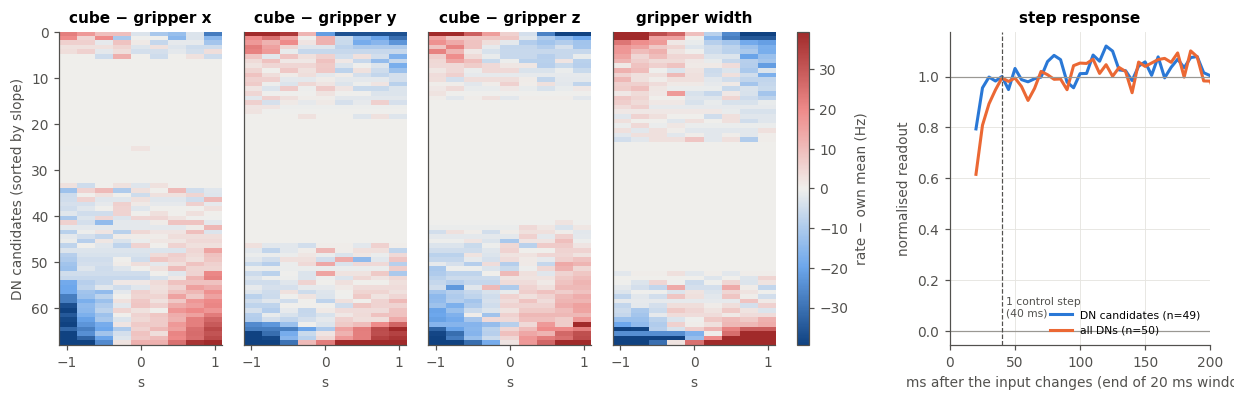

DN candidates modulated by > 10 Hz across a sweep: {'cube − gripper x': 33, 'cube − gripper y': 27, 'cube − gripper z': 31, 'gripper width': 27}
time for the readout to reach 90% of a step (ms): {'DN candidates': 25, 'all DNs': 35}


In [6]:
rows_all = SWEEP[CHOICE][0][0] + SWEEP[CHOICE][1][0]
dnc = POOLS['DN candidates']
levels = np.linspace(-1, 1, 9)
tun = np.zeros((K, len(dnc), len(levels)))
for r in rows_all:
    tun[r['signal'], :, int(round((r['level'] + 1) * 4))] += r['counts'][dnc] * 25.0
tun /= (len(rows_all) / (K * len(levels)))
modul = tun.max(2) - tun.min(2)                                   # Hz, per signal per neuron

# step response: train on settled windows of seed a, decode 20 ms sliding windows of seed b
def step_response(cols):
    curves = []
    for a, b in ((0, 1), (1, 0)):
        Xa, Ya, ga = sweep_xy(SWEEP[CHOICE][a][0], cols)
        trans = SWEEP[CHOICE][b][1]
        for i in range(1, len(trans)):
            pr, cu = trans[i - 1], trans[i]
            if pr['signal'] != cu['signal'] or abs(cu['level'] - pr['level']) < 0.5:
                continue
            k = cu['signal']
            def dec(c):                                           # sliding 20 ms windows, Hz
                cs = np.cumsum(np.r_[np.zeros((1, len(cols))), c[:, cols]], 0)
                return (cs[4:] - cs[:-4]) * 50.0
            npr = len(dec(pr['counts']))
            win = np.r_[dec(pr['counts']), dec(cu['counts'])]
            P, _ = ridge_fit_predict(Xa, Ya, win, ga)
            p = P[:, k]
            before = p[npr - 20:npr].mean()                          # previous level, last 100 ms
            after = p[-20:].mean()                                   # this level, last 100 ms
            if abs(after - before) > 0.2:
                curves.append((p[npr:] - before) / (after - before))
    return np.array(curves)
SR = {p: step_response(c) for p, c in POOLS.items() if p != 'leg MNs'}
t_ms = (np.arange(SR['DN candidates'].shape[1]) + 4) * 5             # window END time after the change

fig = plt.figure(figsize=(13.5, 3.7))
gs = fig.add_gridspec(1, K + 3, width_ratios=[1] * K + [0.07, 0.6, 1.6], wspace=0.15)
dev = tun - tun.mean(2, keepdims=True)                             # change from each neuron's own mean
vm = np.percentile(np.abs(dev), 98)
for k in range(K):
    ax = fig.add_subplot(gs[k])
    order = np.argsort(np.polyfit(levels, dev[k].T, 1)[0])         # sorted by slope for this signal
    im = ax.imshow(dev[k][order], aspect='auto', cmap=DIV, vmin=-vm, vmax=vm,
                   extent=[-1.1, 1.1, len(dnc), 0])
    ax.set_title(LBL[k]); ax.set_xlabel('s'); ax.grid(False)
    if k == 0: ax.set_ylabel('DN candidates (sorted by slope)')
    else: ax.set_yticks([])
fig.colorbar(im, cax=fig.add_subplot(gs[K]), label='rate − own mean (Hz)')
ax = fig.add_subplot(gs[K + 2])
SETTLE = {}
for p, cu in SR.items():
    if len(cu) == 0: continue
    med = np.median(cu, 0)
    ax.plot(t_ms, med, color=POOL_COLOR[p], label=f"{p} (n={len(cu)})")
    above = np.flatnonzero(np.convolve(med >= 0.9, np.ones(4), 'valid') == 4)   # stays above for 20 ms
    SETTLE[p] = int(t_ms[above[0]]) if len(above) else None
for y in (0, 1): ax.axhline(y, color=C['gray'], lw=0.8)
ax.axvline(40, color=C['ink2'], lw=0.8, ls='--')
ax.text(43, 0.05, '1 control step\n(40 ms)', color=C['ink2'], fontsize=7, va='bottom')
ax.set_xlim(0, 200); ax.set_xlabel('ms after the input changes (end of 20 ms window)')
ax.set_ylabel('normalised readout'); ax.set_title('step response'); ax.legend(fontsize=7, loc='lower right')
fig.savefig(OUT / 'step2_tuning.png', bbox_inches='tight'); plt.show()
print("DN candidates modulated by > 10 Hz across a sweep:", {LBL[k]: int((modul[k] > 10).sum()) for k in range(K)})
print("time for the readout to reach 90% of a step (ms):", SETTLE)

## Step 3: replay logged episodes

Each episode: fresh brain (seed = 0 + episode number), held 200 ms at its first state, then one logged state per 40 ms control step, as the closed loop will run. Spikes of the JO-C/E, DN and leg-MN neurons are kept in 5 ms bins, so any window from 5 ms up can be analysed afterwards. About 13 minutes on the laptop.

In [7]:
io = IO[CHOICE]
episodes = [(e, S_ALL[ep_all == e]) for e in EPS]
print(f"replaying {len(episodes)} episodes with the {CHOICE} encoder:")
io.sim_ms = 0.0; io.neuron_counts[:] = 0
REP = replay(io, episodes, W, warmup_ms=200, seed0=0)
NEURON_HZ = io.neuron_counts / (io.sim_ms / 1000)
np.savez_compressed(OUT / f'replay_real_{HOST}.npz', record=RECORD, rows=ROWS, neuron_hz=NEURON_HZ, **REP)
assert np.array_equal(REP['episode'], ep_all[ROWS])
others = np.setdiff1d(np.arange(ws.N), JO)
FRAC_REAL = (NEURON_HZ[others] >= 1).mean()
print(f"network during replay: {FRAC_REAL:.1%} of non-input neurons fire >= 1 Hz; "
      f"DN candidates mean {NEURON_HZ[DN_cand].mean():.1f} Hz ({(NEURON_HZ[DN_cand] >= 1).sum()} of {len(DN_cand)} firing); "
      f"peak memory {peak_mem_gb():.2f} GB")

replaying 60 episodes with the wiring encoder:
  10/60 episodes, 28.2 s brain time, 132 s wall (4.69 s per simulated second)
  20/60 episodes, 55.6 s brain time, 256 s wall (4.60 s per simulated second)
  30/60 episodes, 86.3 s brain time, 447 s wall (5.18 s per simulated second)
  40/60 episodes, 114.0 s brain time, 583 s wall (5.11 s per simulated second)
  50/60 episodes, 139.2 s brain time, 698 s wall (5.02 s per simulated second)
  60/60 episodes, 167.1 s brain time, 854 s wall (5.11 s per simulated second)
network during replay: 4.8% of non-input neurons fire >= 1 Hz; DN candidates mean 40.7 Hz (42 of 68 firing); peak memory 2.38 GB


## Step 4: do the outputs carry the task state? (deliverable)

All scores are **out-of-episode**: 5 folds split by whole episode, ridge penalty chosen inside each training fold.

- **Signals:** R² for each encoded signal, for each readout pool and window (20 / 40 / 50 ms).
- **Ceiling:** the same readout applied to the JO-C/E input spikes themselves (summed per channel). The brain cannot beat this: it is what Poisson noise leaves in the input.
- **Null:** each episode's brain activity paired with the states of a *different* episode at the same step. This keeps everything episodes share over time (they all start with a reach, the brain warms up the same way), so beating it means the readout tracks *this* episode.
- **Also:** phase (8 classes) and, as a week 6 preview, the expert action.

In [8]:
Y = S_ALL[ROWS]; G = REP['episode']; T = REP['step']
N_PERM = 5 if QUICK else 20

def pool_X(R, cols, win):
    return Decoder(cols, win).windows(R['counts'], R['end_bin'])

def channel_X(R, enc, win):
    X = Decoder(JO_COL, win).windows(R['counts'], R['end_bin'])
    return np.stack([X[:, enc.labels == c].mean(1) for c in range(2 * K)], 1)

res = []
for win in (20, 40, 50):
    for p, cols in POOLS.items():
        res.append(dict(readout=p, window_ms=win, **dict(zip(LBL, cv_r2(pool_X(REP, cols, win), Y, G)))))
    res.append(dict(readout='JO input (ceiling)', window_ms=win,
                    **dict(zip(LBL, cv_r2(channel_X(REP, ENC[CHOICE], win), Y, G)))))
res = pd.DataFrame(res); res['median'] = res[LBL].median(axis=1)
display(res.round(3))

X_dn = pool_X(REP, POOLS['DN candidates'], 40)
X_all = pool_X(REP, POOLS['all DNs'], 40)
NULL = null_r2(X_dn, Y, G, T, n_perm=N_PERM)
NULL_ALL = null_r2(X_all, Y, G, T, n_perm=max(5, N_PERM // 2))
prim = res.query("readout == 'DN candidates' and window_ms == 40")[LBL].iloc[0].to_numpy()
allr = res.query("readout == 'all DNs' and window_ms == 40")[LBL].iloc[0].to_numpy()
ceil = res.query("readout == 'JO input (ceiling)' and window_ms == 40")[LBL].iloc[0].to_numpy()

def verdict(r, null):
    beats = r > null.max(0)
    return bool(beats.all() and np.median(r) >= 0.5), beats

PASS, beats = verdict(prim, NULL)
PASS_ALL, beats_all = verdict(allr, NULL_ALL)
print("\nPrimary readout (DN candidates, 40 ms):")
for k in range(K):
    print(f"  {LBL[k]:18s} R² {prim[k]:6.3f}   null max {NULL[:, k].max():6.3f}   ceiling {ceil[k]:6.3f}   "
          f"{'beats null' if beats[k] else 'DOES NOT beat null'}")
print(f"  median R² {np.median(prim):.3f} (needs >= 0.5)")
if PASS:
    NEXT = "PASS: DN-candidate outputs carry the task state. Week 6 reads out from the DN candidates."
elif PASS_ALL:
    NEXT = "DN candidates fail, all DNs pass: widen the week 6 readout to all descending neurons."
elif np.median(ceil) >= 0.5:
    NEXT = "FAIL inside the brain: the input carries the state but the outputs do not. Revisit the input neurons (week 1)."
else:
    NEXT = "FAIL at the input: even the JO spikes do not carry the state well enough. Revisit the encoder rates/window."
print("\n" + NEXT)

,readout,window_ms,cube − gripper x,cube − gripper y,cube − gripper z,gripper width,median
0,DN candidates,20,0.410,0.741,0.759,0.715,0.728
1,all DNs,20,0.580,0.792,0.891,0.812,0.802
2,leg MNs,20,-0.010,0.060,0.024,0.014,0.019
3,JO input (ceiling),20,0.905,0.935,0.969,0.970,0.952
4,DN candidates,40,0.638,0.837,0.881,0.846,0.841
5,all DNs,40,0.762,0.885,0.953,0.899,0.892
6,leg MNs,40,-0.006,0.139,0.044,0.026,0.035
7,JO input (ceiling),40,0.950,0.965,0.984,0.985,0.974
8,DN candidates,50,0.695,0.850,0.904,0.868,0.859
9,all DNs,50,0.793,0.895,0.960,0.908,0.902



Primary readout (DN candidates, 40 ms):
  cube − gripper x   R²  0.638   null max  0.044   ceiling  0.950   beats null
  cube − gripper y   R²  0.837   null max  0.078   ceiling  0.965   beats null
  cube − gripper z   R²  0.881   null max  0.525   ceiling  0.984   beats null
  gripper width      R²  0.846   null max  0.447   ceiling  0.985   beats null
  median R² 0.841 (needs >= 0.5)

PASS: DN-candidate outputs carry the task state. Week 6 reads out from the DN candidates.


In [9]:
# phase, cube position in mm, and the expert action (week 6 preview)
PH = D['phase'][ROWS].astype(int)
phase_acc = {
    'DN candidates': cv_classify(X_dn, PH, G)[0],
    'all DNs': cv_classify(X_all, PH, G)[0],
    'JO input (ceiling)': cv_classify(channel_X(REP, ENC[CHOICE], 40), PH, G)[0],
    'encoded s, no noise': cv_classify(Y, PH, G)[0],
}
print("phase, balanced accuracy (chance 1/%d = %.2f):" % (len(np.unique(PH)), 1 / len(np.unique(PH))),
      {k: round(v, 3) for k, v in phase_acc.items()})

Pdn, _ = cv_predict(X_dn, Y, G)
rel_true = D['obs'][ROWS][:, [OBS_NAMES.index(s) for s in SIGNALS[:3]]]
rel_hat = denormalise(Pdn)[:, :3]
near = np.linalg.norm(rel_true[:, :2], axis=1) < 0.05
POS_MM = {LBL[k]: float(np.median(np.abs(rel_hat[near, k] - rel_true[near, k])) * 1000) for k in range(3)}
print(f"decoded cube position when within 5 cm (x, y) of the gripper, median abs error (mm), "
      f"{near.sum()} steps:", {k: round(v, 1) for k, v in POS_MM.items()})

A = D['act'][ROWS].astype(float)
ACT_NAMES = [str(x) for x in D['act_names']] if 'act_names' in D.files else ['dx', 'dy', 'dz', 'grip']
act = pd.DataFrame({
    'DN candidates': cv_r2(X_dn, A, G), 'all DNs': cv_r2(X_all, A, G),
    'encoded s (linear)': cv_r2(Y, A, G), 'raw 24-value state (linear)': cv_r2(D['obs'][ROWS], A, G)},
    index=ACT_NAMES).T
print("\nexpert action R² from a LINEAR readout (week 6 preview; week 4: linear on raw state = 0% success):")
display(act.round(3))

phase, balanced accuracy (chance 1/8 = 0.12): {'DN candidates': np.float64(0.342), 'all DNs': np.float64(0.404), 'JO input (ceiling)': np.float64(0.324), 'encoded s, no noise': np.float64(0.32)}
decoded cube position when within 5 cm (x, y) of the gripper, median abs error (mm), 3557 steps: {'cube − gripper x': 4.3, 'cube − gripper y': 3.1, 'cube − gripper z': 9.9}

expert action R² from a LINEAR readout (week 6 preview; week 4: linear on raw state = 0% success):


,dx,dy,dz,grip
DN candidates,0.214,0.547,0.241,0.689
all DNs,0.262,0.563,0.259,0.732
encoded s (linear),0.305,0.602,0.219,0.810
raw 24-value state (linear),0.568,0.866,0.768,0.863


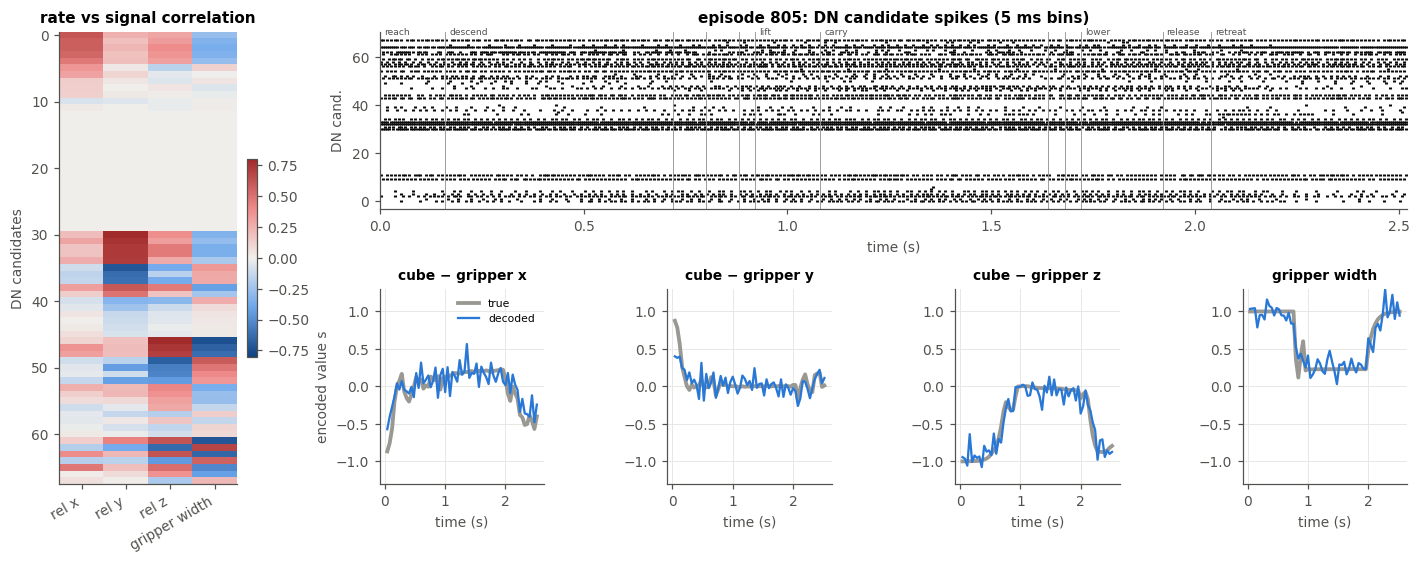

In [10]:
# per-neuron view and one example episode
rho = np.array([[np.corrcoef(X_dn[:, i], Y[:, k])[0, 1] if X_dn[:, i].std() > 0 else 0
                 for k in range(K)] for i in range(X_dn.shape[1])])
o = np.lexsort((-np.abs(rho).max(1), np.abs(rho).argmax(1)))
ex = EPS[np.argmin(np.abs([np.sum(G == e) - np.median([np.sum(G == e) for e in EPS]) for e in EPS]))]
mex = G == ex
fig = plt.figure(figsize=(13, 5.2))
gs = fig.add_gridspec(2, K + 1, width_ratios=[1.2] + [1] * K, height_ratios=[1, 1.1])
ax = fig.add_subplot(gs[:, 0])
im = ax.imshow(rho[o], aspect='auto', cmap=DIV, vmin=-0.8, vmax=0.8); ax.grid(False)
ax.set_xticks(range(K), [l.replace('cube − gripper ', 'rel ') for l in LBL], rotation=30, ha='right')
ax.set_ylabel('DN candidates'); ax.set_title('rate vs signal correlation')
fig.colorbar(im, ax=ax, fraction=0.05)
ax = fig.add_subplot(gs[0, 1:])
eb = REP['end_bin'][mex]; c = REP['counts'][eb[0] - 8:eb[-1], POOLS['DN candidates']][:, o]
tt, nn = np.nonzero(c)
ax.scatter((tt * 5 + 2.5) / 1000, nn, s=1.5, c=C['ink'], marker='|'); ax.grid(False)
ax.set_xlim(0, len(c) * 0.005); ax.set_ylabel('DN cand.'); ax.set_xlabel('time (s)'); ax.set_title(f'episode {ex}: DN candidate spikes (5 ms bins)')
ph = PH[mex]
chg = np.r_[0, np.flatnonzero(np.diff(ph)) + 1, len(ph)]
for a, b in zip(chg[:-1], chg[1:]):
    ax.axvline(a * 0.04, color=C['gray'], lw=0.6)
    if b - a >= 3:                                   # label phases lasting >= 120 ms
        ax.text(a * 0.04 + 0.01, len(o) + 1, PHASE_NAMES[ph[a]], fontsize=6, color=C['ink2'])
tsec = (np.arange(mex.sum()) + 1) * 0.04
for k in range(K):
    ax = fig.add_subplot(gs[1, k + 1])
    ax.plot(tsec, Y[mex, k], color=C['gray'], lw=2.5, label='true')
    ax.plot(tsec, Pdn[mex, k], color=C['blue'], lw=1.5, label='decoded')
    ax.set_title(LBL[k], fontsize=9); ax.set_xlabel('time (s)'); ax.set_ylim(-1.3, 1.3)
    if k == 0: ax.set_ylabel('encoded value s')
    if k == 0: ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(OUT / 'step4_example.png', bbox_inches='tight'); plt.show()

## Step 5: latency

Pair the brain window at step *t* with the arm state at step *t − lag*. If R² peaks at lag 1, the brain reports the state one control step late, and week 6 should either run more brain time per control step or accept a one-step delay. Negative lags (the brain "predicting" the future) give a reference for how much comes just from the state changing smoothly.

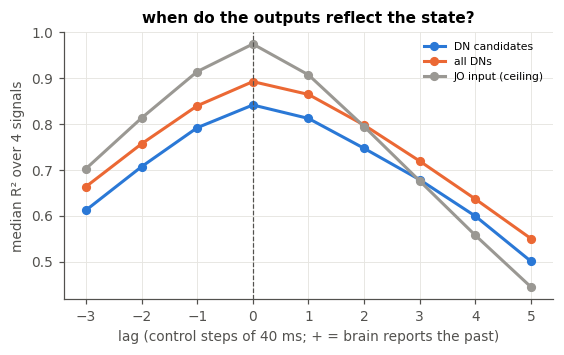

best lag (steps): {'DN candidates': 0, 'all DNs': 0, 'JO input (ceiling)': 0}


In [11]:
LAGS = list(range(-3, 6))
lag_r2 = {p: [] for p in ('DN candidates', 'all DNs', 'JO input (ceiling)')}
X_ch = channel_X(REP, ENC[CHOICE], 40)
for lag in LAGS:
    for p, X in (('DN candidates', X_dn), ('all DNs', X_all), ('JO input (ceiling)', X_ch)):
        Xl, Yl, Gl = lagged(X, Y, G, T, lag)
        lag_r2[p].append(np.median(cv_r2(Xl, Yl, Gl)))
fig, ax = plt.subplots(figsize=(5.2, 3.3))
for p, v in lag_r2.items():
    ax.plot(LAGS, v, marker='o', ms=5, color=POOL_COLOR.get(p, C['gray']), label=p)
ax.axvline(0, color=C['ink2'], lw=0.8, ls='--')
ax.set_xlabel('lag (control steps of 40 ms; + = brain reports the past)'); ax.set_ylabel('median R² over 4 signals')
ax.set_title('when do the outputs reflect the state?'); ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(OUT / 'step5_latency.png'); plt.show()
BEST_LAG = {p: LAGS[int(np.argmax(v))] for p, v in lag_r2.items()}
print("best lag (steps):", BEST_LAG)

## Step 6: shuffled-wiring control

Same replay through a **degree-preserving shuffle** of the full connectome (`shuffle_sub`, as in week 2). As in week 2, random wiring tends to run away, so its `w_syn` is first adjusted (down, or up if it is quieter) until the same share of non-input neurons fires as in the real network under the same encoder (bisection on the scale, 0.7 s of brain time per try). If the real connectome routes task information to the DN candidates better than random wiring at equal activity, the result in Step 4 is a property of the wiring, not of any recurrent network.

Note: matched *overall* activity can still leave the DN candidates quieter in the shuffled network (week 2 saw about 7× less). That is part of the result, so the "all DNs" readout is shown too.

In [12]:
SHUF = None
if RUN_SHUFFLE and not QUICK:
    def frac_firing(engine, scale, enc, seed=99):
        io_ = BrainIO(engine, enc, RECORD); io_.neuron_counts[:] = 0
        io_.reset(seed, scale)
        for x in episodes[0][1][:17]:            # the first 0.68 s of a real episode
            io_.step(x, 40)
        hz = io_.neuron_counts / (io_.sim_ms / 1000)
        return (hz[others] >= 1).mean()
    f_real = frac_firing(eng, W, ENC[CHOICE])
    del IO, io, eng; gc.collect()
    sh_sub = shuffle_sub(full, seed=0)
    eng_s = NumbaLIF(sh_sub, JO, verbose=False)
    f_same = frac_firing(eng_s, W, ENC[CHOICE])
    print(f"real network: {f_real:.1%} firing at w_scale {W}; shuffled at the same scale: {f_same:.1%}")
    # bisection in log space, turning the scale down (runaway) or up (too quiet) until activity matches
    lo, hi = (0.02 * W, W) if f_same > f_real else (W, 4 * W)
    for it in range(8):
        mid = np.sqrt(lo * hi)
        f = frac_firing(eng_s, mid, ENC[CHOICE])
        lo, hi = (mid, hi) if f < f_real else (lo, mid)
        print(f"  try {mid:.3f}: {f:.1%}")
    W_S = np.sqrt(lo * hi)
    io_s = BrainIO(eng_s, ENC[CHOICE], RECORD)
    print(f"shuffled network at w_scale {W_S:.3f}; replaying:")
    REP_S = replay(io_s, episodes, W_S, warmup_ms=200, seed0=0)
    HZ_S = io_s.neuron_counts / (io_s.sim_ms / 1000)
    np.savez_compressed(OUT / f'replay_shuffled_{HOST}.npz', record=RECORD, neuron_hz=HZ_S, w_scale=W_S, **REP_S)
    SHUF = pd.DataFrame({
        'real': [FRAC_REAL, NEURON_HZ[DN_cand].mean(), NEURON_HZ[ALL_DN].mean(), *prim, np.median(prim), np.median(allr)],
        'shuffled': [(HZ_S[others] >= 1).mean(), HZ_S[DN_cand].mean(), HZ_S[ALL_DN].mean(),
                     *cv_r2(pool_X(REP_S, POOLS['DN candidates'], 40), Y, G),
                     np.median(cv_r2(pool_X(REP_S, POOLS['DN candidates'], 40), Y, G)),
                     np.median(cv_r2(pool_X(REP_S, POOLS['all DNs'], 40), Y, G))]},
        index=['share of neurons firing', 'DN candidates mean Hz', 'all DNs mean Hz',
               *[f'R² {l} (DN cand.)' for l in LBL], 'median R² (DN cand.)', 'median R² (all DNs)'])
    display(SHUF.round(3))
    del eng_s, io_s; gc.collect()
else:
    print("skipped (QUICK or RUN_SHUFFLE = False)")

real network: 4.7% firing at w_scale 0.7; shuffled at the same scale: 0.9%
  try 1.400: 22.9%
  try 0.990: 2.7%
  try 1.177: 5.8%
  try 1.080: 3.8%
  try 1.127: 4.7%
  try 1.152: 5.1%
  try 1.140: 4.9%
  try 1.133: 4.7%
shuffled network at w_scale 1.137; replaying:
  10/60 episodes, 28.2 s brain time, 118 s wall (4.19 s per simulated second)
  20/60 episodes, 55.6 s brain time, 228 s wall (4.10 s per simulated second)
  30/60 episodes, 86.3 s brain time, 393 s wall (4.55 s per simulated second)
  40/60 episodes, 114.0 s brain time, 508 s wall (4.45 s per simulated second)
  50/60 episodes, 139.2 s brain time, 608 s wall (4.37 s per simulated second)
  60/60 episodes, 167.1 s brain time, 720 s wall (4.31 s per simulated second)


,real,shuffled
share of neurons firing,0.048,0.045
DN candidates mean Hz,40.684,1.217
all DNs mean Hz,12.550,1.355
R² cube − gripper x (DN cand.),0.638,0.095
R² cube − gripper y (DN cand.),0.837,0.069
R² cube − gripper z (DN cand.),0.881,0.471
R² gripper width (DN cand.),0.846,0.471
median R² (DN cand.),0.841,0.283
median R² (all DNs),0.892,0.807


## Step 7: summary figure and results file

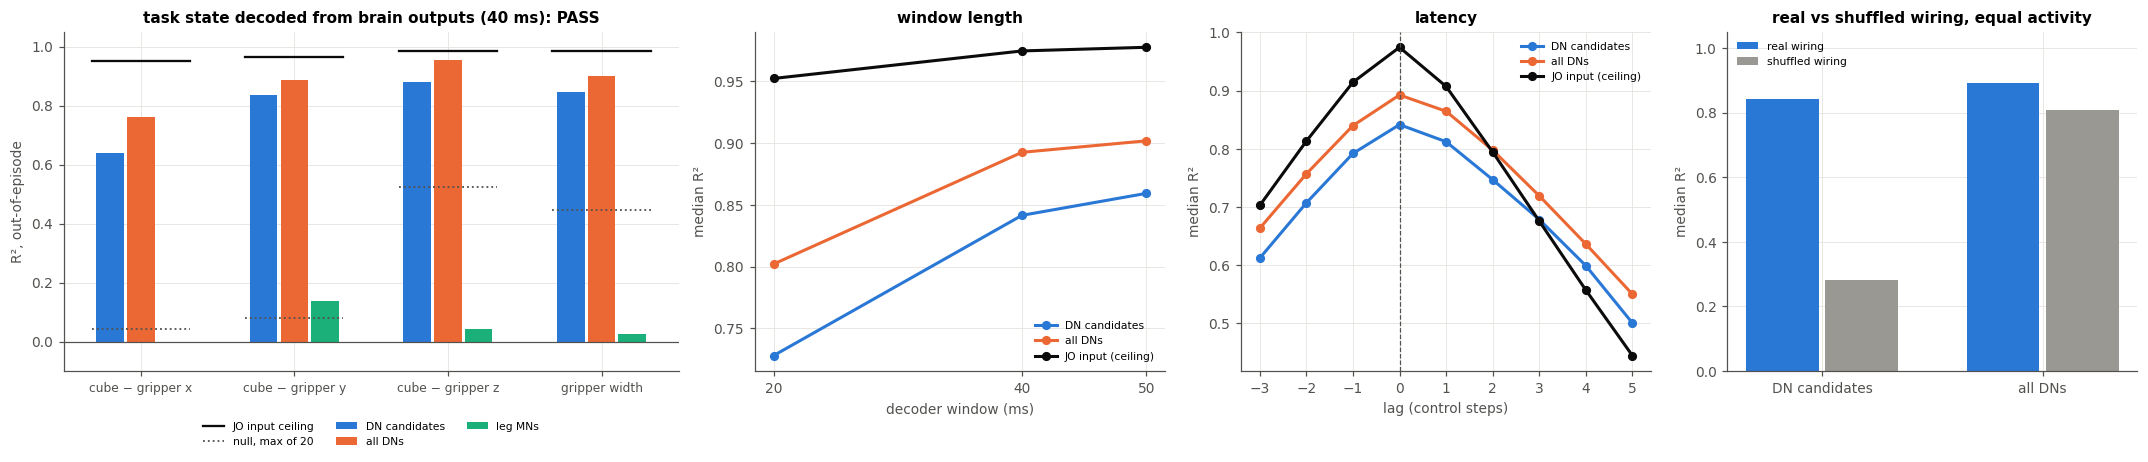

PASS: DN-candidate outputs carry the task state. Week 6 reads out from the DN candidates.
total 36 min. Send me week5_results_laptop.json and the PNGs in /home/notlord/arm_simulation/brain/data/week5.


In [13]:
n_pan = 4 if SHUF is not None else 3
fig, axs = plt.subplots(1, n_pan, figsize=(4.4 * n_pan + 2, 4.3), gridspec_kw=dict(width_ratios=[1.5] + [1] * (n_pan - 1)))
ax = axs[0]
r40 = res[res.window_ms == 40].set_index('readout')
bars = [('DN candidates', C['blue']), ('all DNs', C['orange']), ('leg MNs', C['aqua'])]
wd = 0.2
for j, (p, cl) in enumerate(bars):
    ax.bar(np.arange(K) + (j - 1) * wd, r40.loc[p, LBL], wd * 0.9, color=cl, label=p)
for k in range(K):
    ax.plot([k - 1.6 * wd, k + 1.6 * wd], [ceil[k]] * 2, color=C['ink'], lw=1.5, label='JO input ceiling' if k == 0 else None)
    ax.plot([k - 1.6 * wd, k + 1.6 * wd], [NULL[:, k].max()] * 2, color=C['ink2'], lw=1.2, ls=':',
            label='null, max of %d' % N_PERM if k == 0 else None)
ax.axhline(0, color=C['ink2'], lw=0.8)
ax.set_xticks(range(K), LBL, fontsize=8); ax.set_ylabel('R², out-of-episode'); ax.set_ylim(min(-0.1, ax.get_ylim()[0]), 1.05)
ax.set_title(f"task state decoded from brain outputs (40 ms): {'PASS' if PASS else 'FAIL'}")
ax.legend(fontsize=7, ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.12))
ax = axs[1]
for p, cl in bars[:2] + [('JO input (ceiling)', C['ink'])]:
    v = res[res.readout == p].sort_values('window_ms')
    ax.plot(v.window_ms, v['median'], marker='o', ms=5, color=cl, label=p)
ax.set_xticks([20, 40, 50]); ax.set_xlabel('decoder window (ms)'); ax.set_ylabel('median R²')
ax.set_title('window length'); ax.legend(fontsize=7)
ax = axs[2]
for p, v in lag_r2.items():
    ax.plot(LAGS, v, marker='o', ms=5, color=POOL_COLOR.get(p, C['ink']), label=p)
ax.axvline(0, color=C['ink2'], lw=0.8, ls='--')
ax.set_xlabel('lag (control steps)'); ax.set_ylabel('median R²'); ax.set_title('latency'); ax.legend(fontsize=7)
if SHUF is not None:
    ax = axs[3]
    keys = ['median R² (DN cand.)', 'median R² (all DNs)']
    for j, (nm, cl) in enumerate((('real', C['blue']), ('shuffled', C['gray']))):
        ax.bar(np.arange(2) + (j - 0.5) * 0.36, SHUF.loc[keys, nm], 0.33, color=cl, label=f"{nm} wiring")
    ax.set_xticks([0, 1], ['DN candidates', 'all DNs']); ax.set_ylim(0, 1.05); ax.set_ylabel('median R²')
    ax.set_title('real vs shuffled wiring, equal activity'); ax.legend(fontsize=7, loc='upper left')
fig.tight_layout(); fig.savefig(OUT / f'week5_summary_{HOST}.png', bbox_inches='tight'); plt.show()

summary = dict(
    host=HOST, quick=QUICK, w_scale=W, encoder=CHOICE, episodes=len(EPS), steps=int(len(ROWS)),
    sweep_scores=tab.reset_index().astype({'level_0': str, 'level_1': str}).to_dict('records'),
    settle_ms=SETTLE, r2=res.to_dict('records'),
    null_max_dn=dict(zip(LBL, NULL.max(0).tolist())), null_max_all=dict(zip(LBL, NULL_ALL.max(0).tolist())),
    pass_primary=PASS, pass_all_dn=PASS_ALL, next=NEXT, phase_bal_acc=phase_acc, pos_err_mm_near=POS_MM,
    action_r2=act.to_dict(), best_lag=BEST_LAG, lag_r2={k: dict(zip(LAGS, v)) for k, v in lag_r2.items()},
    frac_firing_real=float(FRAC_REAL), shuffled=None if SHUF is None else SHUF.to_dict(),
    wall_min=(time.perf_counter() - T_START) / 60)
(OUT / f'week5_results_{HOST}.json').write_text(json.dumps(summary, indent=1, default=float))
print(NEXT)
print(f"total {summary['wall_min']:.0f} min. Send me week5_results_{HOST}.json and the PNGs in {OUT}.")